# Smart Workforce & Resource Scheduling Optimization
## Notebook 2: Staffing Gap Analysis

In this notebook I test whether the staffing gap (`active_agents - required_fte`) follows a pattern, or looks like random variation.

Input: `data/clean/call_center_clean.csv` (created in Notebook 1).

Before I calculate any gap, I first check what the staffing columns really mean.

## 1. Setup

In [27]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)

In [28]:
PROJECT_ROOT = Path("..")
CLEAN_FILE = PROJECT_ROOT / "data" / "clean" / "call_center_clean.csv"

SECONDS_PER_HOUR = 3600
SECONDS_PER_SHIFT = 8 * SECONDS_PER_HOUR  # 28,800 seconds = one 8-hour shift

EXPECTED_ROWS = 9970
EXPECTED_FLAGGED = 632

## 2. Load the clean data and validate it
The clean file should match the result of Notebook 1: 9,970 rows and 632 flagged rows. If it does not, the code stops with an error.

In [29]:
df = pd.read_csv(CLEAN_FILE, parse_dates=["date"])

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Rows flagged by zero_staff_flag: {df['zero_staff_flag'].sum()}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Types: date = {df['date'].dtype}, zero_staff_flag = {df['zero_staff_flag'].dtype}")

assert df.shape[0] == EXPECTED_ROWS, "Unexpected number of rows"
assert df["zero_staff_flag"].sum() == EXPECTED_FLAGGED, "Unexpected number of flagged rows"

Rows: 9,970 | Columns: 30
Rows flagged by zero_staff_flag: 632
Date range: 2021-01-01 to 2026-10-03
Types: date = datetime64[us], zero_staff_flag = bool


## 3. Definition checks
Before I calculate the gap, I check what `required_fte` and `active_agents` really measure:
1. Is `required_fte` calculated from the workload (`handle_time_total`)?
2. Does it describe people working at the same time in one hour, or an 8-hour workload equivalent?
3. What are the rows with `zero_staff_flag`?

### 3.1 How is `required_fte` calculated?
`handle_time_total` is in seconds, and one 8-hour shift is 28,800 seconds. If `required_fte = floor(handle_time_total / 28,800)`, then `required_fte` is the workload counted in shifts.

In [30]:
required_from_workload = np.floor(df["handle_time_total"] / SECONDS_PER_SHIFT)
formula_holds = required_from_workload == df["required_fte"]

print(f"required_fte = floor(handle_time_total / {SECONDS_PER_SHIFT:,}) in {formula_holds.sum():,} / {len(df):,} rows")

required_fte = floor(handle_time_total / 28,800) in 9,970 / 9,970 rows


### 3.2 One hour, or an 8-hour equivalent?
Each row is one queue in one hour. If `active_agents` were people working at the same time, the workload in hours could not be bigger than the number of agents. For example, 4 agents can work at most 4 hours in one hour. I leave out the flagged rows here (they have no active agents) and compare the two numbers.

In [31]:
analysis = df.loc[~df["zero_staff_flag"]].copy()
assert (analysis["active_agents"] > 0).all()

analysis["workload_hours"] = analysis["handle_time_total"] / SECONDS_PER_HOUR
analysis["implied_occupancy_pct"] = analysis["workload_hours"] / analysis["active_agents"] * 100

print(f"Rows in the primary analysis: {len(analysis):,}")
print(f"Median workload per row:   {analysis['workload_hours'].median():.1f} agent-hours")
print(f"Median active agents:      {analysis['active_agents'].median():.1f}")
print(f"Rows where workload hours > active agents: {(analysis['workload_hours'] > analysis['active_agents']).mean():.1%}")
print(f"Median implied occupancy:  {analysis['implied_occupancy_pct'].median():.0f}%")
print(f"Median reported occupancy: {analysis['occupancy_percent'].median():.0f}%")

Rows in the primary analysis: 9,338
Median workload per row:   36.4 agent-hours
Median active agents:      4.0
Rows where workload hours > active agents: 100.0%
Median implied occupancy:  904%
Median reported occupancy: 75%


### 3.3 What are the flagged rows?
`required_fte` uses `floor`, so a workload under one 8-hour shift gives 0. I compare the flag with "workload under 8 hours".

In [32]:
below_one_shift = df["handle_time_total"] < SECONDS_PER_SHIFT

pd.crosstab(
    df["zero_staff_flag"],
    below_one_shift,
    rownames=["zero_staff_flag"],
    colnames=["workload below 8 hours"],
)

workload below 8 hours,False,True
zero_staff_flag,,
False,9338,0
True,0,632


### Findings: definition checks
- `required_fte` is not an independent estimate. In all 9,970 rows it equals `floor(handle_time_total / 28,800)`, so it comes straight from the workload.
- The staffing numbers are not real hourly headcounts. The median workload is 36.4 agent-hours per row, but the median `active_agents` is only 4. If I read them as people working at the same time, the occupancy would be about 904%, which is impossible. The reported `occupancy_percent` has a median of 75%.
- The 632 flagged rows are a rounding effect. Their workload is under 8 hours (28,800 seconds), so `floor` gives 0. All flagged rows have this and no other row does. These are small hours, not hours without staff.
- So `active_agents - required_fte` is a plan-versus-actual difference on an 8-hour scale. I do not read it as a real hourly staffing gap.

## 4. Derived and independent columns
Before I compare staffing with service quality, I check which columns are calculated from other columns and which ones move on their own.

### 4.1 Is `wait_time_avg` a separate measure?

In [33]:
check_wait = analysis["abandoned_volume"] / analysis["offered_volume"] * analysis["aht_seconds"]
wait_matches = np.isclose(check_wait, analysis["wait_time_avg"], atol=0.001)

print(f"wait_time_avg = abandoned / offered x AHT in {wait_matches.sum():,} / {len(analysis):,} rows")

wait_time_avg = abandoned / offered x AHT in 9,338 / 9,338 rows


### 4.2 Does abandonment grow with volume?
I split the rows into four groups by offered volume and compare the abandoned volume and the abandonment rate.

In [34]:
analysis["abandon_rate"] = analysis["abandoned_volume"] / analysis["offered_volume"]
analysis["volume_group"] = pd.qcut(analysis["offered_volume"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

print(f"Correlation offered vs abandoned volume: {analysis['offered_volume'].corr(analysis['abandoned_volume']):.3f}")

analysis.groupby("volume_group", observed=True).agg(
    avg_offered=("offered_volume", "mean"),
    avg_abandoned=("abandoned_volume", "mean"),
    avg_abandon_rate=("abandon_rate", "mean"),
).round(3)

Correlation offered vs abandoned volume: 0.032


,avg_offered,avg_abandoned,avg_abandon_rate
volume_group,,,
Q1 (lowest),130.548,14.091,0.116
Q2,242.586,15.280,0.064
Q3,349.640,14.841,0.043
Q4 (highest),455.371,15.010,0.033


### 4.3 Are the quality columns linked to workload or staffing?
I check how four quality columns correlate with the workload and staffing columns.

In [35]:
quality_cols = ["service_level_percent", "occupancy_percent", "utilization_percent", "shrinkage_percent"]
driver_cols = ["offered_volume", "aht_seconds", "handle_time_total", "required_fte", "active_agents", "abandoned_volume"]

corr_table = analysis[quality_cols + driver_cols].corr().loc[quality_cols, driver_cols].round(3)
print(corr_table)
print("\nStrongest absolute correlation per column:")
print(corr_table.abs().max(axis=1))

                       offered_volume  aht_seconds  handle_time_total  \
service_level_percent          -0.011        0.004             -0.010   
occupancy_percent              -0.007        0.005             -0.003   
utilization_percent            -0.002        0.004             -0.002   
shrinkage_percent               0.001        0.001              0.002   

                       required_fte  active_agents  abandoned_volume  
service_level_percent        -0.009         -0.006            -0.013  
occupancy_percent            -0.003         -0.003             0.010  
utilization_percent          -0.002          0.168             0.018  
shrinkage_percent             0.001          0.073            -0.011  

Strongest absolute correlation per column:
service_level_percent    0.013
occupancy_percent        0.010
utilization_percent      0.168
shrinkage_percent        0.073
dtype: float64


### Findings: derived and independent columns
- `wait_time_avg` is not a separate measure. In all 9,338 rows it equals abandoned volume divided by offered volume, times AHT, so it says the same as the abandonment rate.
- Abandoned volume does not grow with volume. It stays at about 14 to 15 contacts in every volume group (correlation 0.03), so the abandonment rate falls from 11.6% to 3.3% when volume goes up. When I compare abandonment between groups, I have to take volume into account.
- `service_level_percent` and `occupancy_percent` are not related to volume, handling time or staffing (all correlations below 0.02). `utilization_percent` and `shrinkage_percent` have small links with `active_agents` (0.17 and 0.07). I did not check why.
- So if I find no link between staffing gaps and service quality later, that says more about how this dataset was built than about real call centers.

## 5. Staffing gap and staffing status
`gap = active_agents - required_fte`, for the 9,338 rows of the main analysis (flagged rows left out). The unit is FTE on the 8-hour scale from section 3, so the gap compares plan and actual inside this dataset.

- gap < 0: Understaffed
- gap = 0: Matched
- gap > 0: Overstaffed

In [36]:
analysis["gap"] = analysis["active_agents"] - analysis["required_fte"]

status_order = ["Understaffed", "Matched", "Overstaffed"]
analysis["staffing_status"] = pd.Categorical(
    np.select([analysis["gap"] < 0, analysis["gap"] == 0], ["Understaffed", "Matched"], default="Overstaffed"),
    categories=status_order,
    ordered=True,
)

print(f"Gap range: {analysis['gap'].min()} to {analysis['gap'].max()} FTE")
print(f"Rows without a status: {analysis['staffing_status'].isna().sum()}")

Gap range: -3 to 4 FTE
Rows without a status: 0


### 5.1 How often is each status?

In [37]:
status_summary = analysis["staffing_status"].value_counts().reindex(status_order).to_frame("rows")
status_summary["share_pct"] = (status_summary["rows"] / len(analysis) * 100).round(1)
status_summary

,rows,share_pct
staffing_status,,
Understaffed,1861,19.9
Matched,5301,56.8
Overstaffed,2176,23.3


### 5.2 How big are the gaps?

In [38]:
gap_counts = analysis["gap"].value_counts().sort_index().to_frame("rows")
gap_counts["share_pct"] = (gap_counts["rows"] / len(analysis) * 100).round(1)
print(gap_counts)

within_one = (analysis["gap"].abs() <= 1).mean()
shortage = -analysis.loc[analysis["gap"] < 0, "gap"].sum()
surplus = analysis.loc[analysis["gap"] > 0, "gap"].sum()

print(f"\nRows within +/- 1 FTE: {within_one:.1%}")
print(f"Sum of negative gaps: {shortage:,} FTE | Sum of positive gaps: {surplus:,} FTE (sample sums, for reproduction only)")

     rows  share_pct
gap                 
-3     16        0.2
-2    234        2.5
-1   1611       17.3
 0   5301       56.8
 1   1907       20.4
 2    231        2.5
 3     36        0.4
 4      2        0.0

Rows within +/- 1 FTE: 94.4%
Sum of negative gaps: 2,127 FTE | Sum of positive gaps: 2,485 FTE (sample sums, for reproduction only)


### Findings: staffing gap
- 56.8% of the rows are matched, 19.9% are understaffed and 23.3% are overstaffed. These match the first numbers I got in my early test.
- The gaps are small. 94.4% of the rows are within one FTE of the plan. The largest gaps are 3 FTE short and 4 FTE over.
- Overstaffed rows are a bit more frequent than understaffed rows. But this only describes plan versus actual in this dataset. It does not prove real overstaffing.
- The sums of the negative and positive gaps (2,127 and 2,485 FTE) are sample sums. I do not use them to say that extra staff could cover a shortage.

## 6. Where do the gaps concentrate?
Question 2: do understaffed rows gather in certain queues, hours, weekdays or sites?

I use a Chi-square test. It asks: if the share of understaffed rows were the same in every group, how likely is it to see differences this big by chance? A p-value above 0.05 means the differences look like chance. It does not prove that the gaps are random.

### 6.1 Queue, site, hour, weekday, channel, region, business unit

In [39]:
from scipy.stats import chi2_contingency

analysis["is_understaffed"] = analysis["gap"] < 0
overall_rate = analysis["is_understaffed"].mean()
print(f"Overall share of understaffed rows: {overall_rate:.1%}\n")

dimensions = ["queue_name", "site", "hour", "weekday", "channel", "region", "business_unit"]
results = []

for dim in dimensions:
    table = pd.crosstab(analysis[dim], analysis["is_understaffed"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    group_share = analysis.groupby(dim)["is_understaffed"].mean() * 100
    group_size = analysis.groupby(dim).size()
    margin = 1.96 * np.sqrt(overall_rate * (1 - overall_rate) / group_size.median()) * 100

    results.append({
        "dimension": dim,
        "groups": len(group_size),
        "median_rows_per_group": int(group_size.median()),
        "lowest_share_pct": group_share.min(),
        "highest_share_pct": group_share.max(),
        "margin_pct_points": margin,
        "p_value": p_value,
    })

concentration = pd.DataFrame(results).round(3)
concentration

Overall share of understaffed rows: 19.9%



,dimension,groups,median_rows_per_group,lowest_share_pct,highest_share_pct,margin_pct_points,p_value
0,queue_name,20,418,17.241,22.222,3.827,0.996
1,site,58,172,13.372,31.481,5.970,0.113
2,hour,24,388,17.241,23.177,3.972,0.883
3,weekday,7,1339,18.759,21.285,2.140,0.781
4,channel,3,3096,19.551,20.480,1.407,0.631
5,region,3,3130,19.489,20.165,1.399,0.751
6,business_unit,5,1840,18.514,21.114,1.825,0.316


### 6.2 Workload size
`required_fte` shows how big the workload of a row is. I group it into four bands and compare the status shares.

In [40]:
analysis["workload_band"] = pd.cut(analysis["required_fte"], bins=[0, 2, 5, 8, 15], labels=["1-2", "3-5", "6-8", "9-15"])

band_share = (pd.crosstab(analysis["workload_band"], analysis["staffing_status"], normalize="index") * 100).round(1)
band_share.insert(0, "rows", analysis["workload_band"].value_counts().sort_index())
print(band_share)

band_table = pd.crosstab(analysis["workload_band"], analysis["staffing_status"])
print(f"\nChi-square p-value (workload band vs status): {chi2_contingency(band_table)[1]:.4f}")

mismatch_small = 100 - band_share.loc["1-2", "Matched"]
mismatch_large = 100 - band_share.loc["9-15", "Matched"]
print(f"Mismatch in 1-2 FTE rows: {mismatch_small:.1f}% | in 9-15 FTE rows: {mismatch_large:.1f}% | ratio: {mismatch_large / mismatch_small:.1f}")

one_fte = analysis.loc[analysis["required_fte"] == 1]
print(f"Rows with required_fte = 1: {len(one_fte):,} | matched: {(one_fte['gap'] == 0).mean():.0%}")

staffing_status  rows  Understaffed  Matched  Overstaffed
workload_band                                            
1-2              2776           7.9     81.2         10.9
3-5              3280          14.3     61.7         24.0
6-8              1883          33.6     38.1         28.4
9-15             1399          38.7     21.8         39.5

Chi-square p-value (workload band vs status): 0.0000
Mismatch in 1-2 FTE rows: 18.8% | in 9-15 FTE rows: 78.2% | ratio: 4.2
Rows with required_fte = 1: 1,346 | matched: 100%


### 6.3 Is it a real difference or an integer effect?
Agents are whole numbers. One agent more or less is a big share of a small workload and a small share of a large one. I measure the gap relative to the plan, only for rows that are not matched.

In [41]:
mismatched = analysis.loc[analysis["gap"] != 0].copy()
mismatched["relative_gap_pct"] = (mismatched["gap"].abs() / mismatched["required_fte"] * 100)

mismatched.groupby("workload_band", observed=True)["relative_gap_pct"].mean().round(1)

workload_band
1-2     50.0
3-5     26.3
6-8     16.0
9-15    13.2
Name: relative_gap_pct, dtype: float64

### Findings: where the gaps concentrate
- The share of understaffed rows is about 20% in every queue, hour, weekday, channel, region and business unit. None of the Chi-square tests is significant (all p-values above 0.3, except site with 0.113). So I see no statistically detectable pattern in these dimensions. That does not prove that the gaps are random.
- The groups have 170 to 420 rows, so the share of a group is only known within about 4 to 6 points (queues, hours, sites). Small differences could be hidden in this sample.
- Workload size is the one clear difference (p < 0.0001). 78.2% of the rows with 9-15 FTE are mismatched, against 18.8% of the rows with 1-2 FTE. That is about 4.2 times more.
- This is mostly an integer effect. All 1,346 rows with `required_fte = 1` are matched. When a small row is mismatched, one agent is 50% of the plan, against about 13% in large rows. So I should not rank queues by how often they are mismatched.

## 7. Does understaffing relate to service quality?
Question 3. I compare abandonment, waiting time and service level between the three statuses. First for all rows, then only between rows with the same workload (`required_fte`), because section 4.2 showed that volume changes the abandonment rate. These are descriptive comparisons. They do not show cause and effect.

### 7.1 All rows

In [42]:
analysis["abandon_rate_pct"] = analysis["abandon_rate"] * 100

overall_compare = analysis.groupby("staffing_status", observed=True).agg(
    rows=("gap", "size"),
    avg_offered=("offered_volume", "mean"),
    avg_aht_seconds=("aht_seconds", "mean"),
    avg_abandon_rate_pct=("abandon_rate_pct", "mean"),
    avg_wait_seconds=("wait_time_avg", "mean"),
    median_wait_seconds=("wait_time_avg", "median"),
    avg_service_level=("service_level_percent", "mean"),
).round(2)
print(overall_compare)

print(f"\nCorrelation gap vs service level: {analysis['gap'].corr(analysis['service_level_percent']):.3f}")
print(f"Correlation gap vs abandon rate:  {analysis['gap'].corr(analysis['abandon_rate']):.3f}")

                 rows  avg_offered  avg_aht_seconds  avg_abandon_rate_pct  \
staffing_status                                                             
Understaffed     1861       352.00           624.73                  4.65   
Matched          5301       256.91           508.77                  7.53   
Overstaffed      2176       334.92           598.33                  5.20   

                 avg_wait_seconds  median_wait_seconds  avg_service_level  
staffing_status                                                            
Understaffed                29.39                23.16              82.35  
Matched                     41.23                24.83              82.50  
Overstaffed                 32.06                24.16              82.55  

Correlation gap vs service level: 0.013
Correlation gap vs abandon rate:  0.014


### 7.2 Rows with the same workload
I compare the statuses only between rows with the same `required_fte`, so volume cannot explain the difference. I keep the workload levels that have at least 30 rows in each status.

In [43]:
level_counts = pd.crosstab(analysis["required_fte"], analysis["staffing_status"])
comparable_levels = level_counts.index[(level_counts >= 30).all(axis=1)]
print(f"Workload levels with at least 30 rows in every status: {comparable_levels.min()} to {comparable_levels.max()} FTE ({len(comparable_levels)} levels)")

same_workload = analysis.loc[analysis["required_fte"].isin(comparable_levels)]

abandon_by_level = same_workload.pivot_table(index="required_fte", columns="staffing_status", values="abandon_rate_pct", observed=True)
abandon_by_level.round(1)

Workload levels with at least 30 rows in every status: 2 to 12 FTE (11 levels)


staffing_status,Understaffed,Matched,Overstaffed
required_fte,,,
2,8.3,8.0,8.4
3,6.3,6.2,6.7
4,5.7,5.4,5.6
5,4.7,5.1,5.2
6,4.3,4.6,4.4
7,4.1,3.8,4.4
8,3.8,3.6,3.8
9,3.3,3.6,3.8
10,3.3,3.4,3.3


In [44]:
service_by_level = same_workload.pivot_table(index="required_fte", columns="staffing_status", values="service_level_percent", observed=True)
service_by_level.round(1)

staffing_status,Understaffed,Matched,Overstaffed
required_fte,,,
2,82.9,82.1,82.1
3,82.8,82.5,82.1
4,82.8,82.7,83.3
5,82.5,82.7,82.6
6,82.8,82.5,83.1
7,82.4,82.0,82.5
8,81.9,82.1,82.9
9,82.0,82.5,82.1
10,82.3,82.7,82.2


In [45]:
summary = pd.DataFrame({
    "abandon_rate_pct_points": [
        (abandon_by_level["Understaffed"] - abandon_by_level["Matched"]).mean(),
        (abandon_by_level["Overstaffed"] - abandon_by_level["Matched"]).mean(),
    ],
    "service_level_points": [
        (service_by_level["Understaffed"] - service_by_level["Matched"]).mean(),
        (service_by_level["Overstaffed"] - service_by_level["Matched"]).mean(),
    ],
    "levels_where_service_level_higher": [
        (service_by_level["Understaffed"] > service_by_level["Matched"]).sum(),
        (service_by_level["Overstaffed"] > service_by_level["Matched"]).sum(),
    ],
}, index=["Understaffed vs Matched", "Overstaffed vs Matched"]).round(2)

print(f"Number of compared workload levels: {len(comparable_levels)}")
summary

Number of compared workload levels: 11


,abandon_rate_pct_points,service_level_points,levels_where_service_level_higher
Understaffed vs Matched,-0.01,-0.49,5
Overstaffed vs Matched,0.11,-0.19,4


### Findings: staffing and service quality
- At first sight understaffed rows look better: abandonment is 4.7% against 7.5% for matched rows, and the mean wait is 29 s against 41 s. But understaffed rows also have more volume (352 against 257 offered contacts), and the abandonment rate falls when volume grows (section 4.2).
- Between rows with the same `required_fte` (2 to 12 FTE), the abandonment difference is close to zero: -0.01 points for understaffed and +0.11 points for overstaffed, both compared with matched.
- Service level is about 82.5% in all three groups. At the same workload the average difference is below half a point, and the direction changes between levels (understaffed is higher than matched in 5 of 11 levels). The levels with 11 and 12 FTE have small groups and vary more.
- The median wait is 23 to 25 s in all statuses. The higher mean for matched rows comes from a few long waits.
- So I see no link between the staffing gap and service quality in this data. This fits section 4: service level and occupancy are not related to workload or staffing in this dataset. It is a description, not proof of cause and effect, and it says little about real call centers.

## 8. Charts and final analysis table
I make three charts, one for each question, and save them as PNG files for the README and the presentation. At the end I save the analysis table for SQLite and Tableau.

In [46]:
import matplotlib.pyplot as plt

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
UNDER, MATCHED, OVER, BLUE = "#e34948", "#898781", "#2a78d6", "#2a78d6"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK_2, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
})

### Chart 1: How big are the gaps?

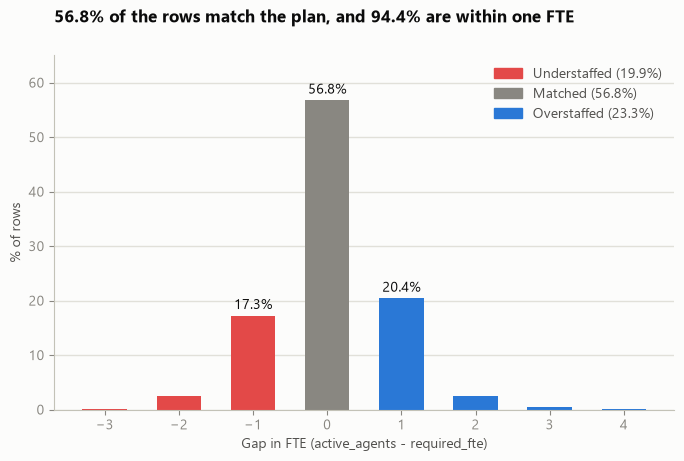

In [47]:
gap_share = analysis["gap"].value_counts(normalize=True).sort_index() * 100
bar_colors = [UNDER if g < 0 else MATCHED if g == 0 else OVER for g in gap_share.index]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.bar(gap_share.index, gap_share.values, width=0.6, color=bar_colors)

for g in [-1, 0, 1]:
    ax.text(g, gap_share[g] + 1.2, f"{gap_share[g]:.1f}%", ha="center", color=INK, fontsize=10)

ax.set_xticks(gap_share.index)
ax.set_xlabel("Gap in FTE (active_agents - required_fte)")
ax.set_ylabel("% of rows")
ax.set_ylim(0, 65)
fig.suptitle("56.8% of the rows match the plan, and 94.4% are within one FTE", x=0.125, ha="left", color=INK, fontweight="bold", fontsize=12)

status_share = analysis["staffing_status"].value_counts(normalize=True) * 100
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UNDER, MATCHED, OVER)]
labels = [f"{s} ({status_share[s]:.1f}%)" for s in status_order]
ax.legend(handles, labels, frameon=False, loc="upper right")

fig.savefig(FIG_DIR / "01_gap_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Chart 2: Which rows miss the plan?

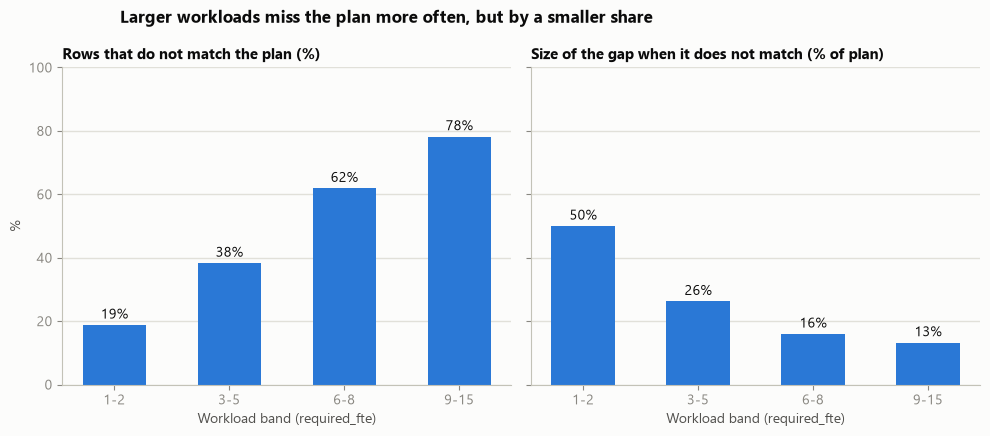

In [48]:
mismatch_share = 100 - band_share["Matched"]
gap_size = mismatched.groupby("workload_band", observed=True)["relative_gap_pct"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
panels = [
    (axes[0], mismatch_share, "Rows that do not match the plan (%)"),
    (axes[1], gap_size, "Size of the gap when it does not match (% of plan)"),
]
for ax, values, title in panels:
    ax.bar(values.index.astype(str), values.values, width=0.55, color=BLUE)
    for x, v in enumerate(values.values):
        ax.text(x, v + 2, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
    ax.set_title(title)
    ax.set_xlabel("Workload band (required_fte)")
    ax.set_ylim(0, 100)

axes[0].set_ylabel("%")
fig.suptitle("Larger workloads miss the plan more often, but by a smaller share", x=0.125, ha="left", color=INK, fontweight="bold", fontsize=12)
fig.tight_layout()

fig.savefig(FIG_DIR / "02_mismatch_by_workload.png", dpi=150, bbox_inches="tight")
plt.show()

### Chart 3: Does understaffing relate to abandonment?

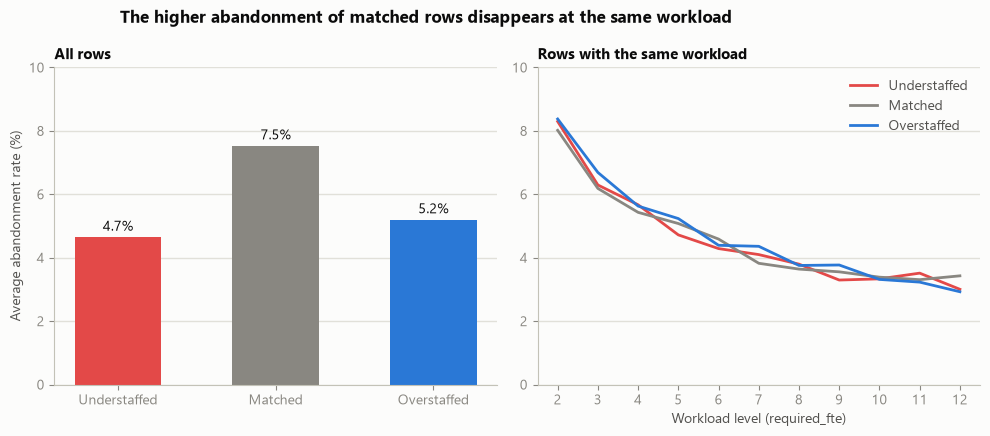

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))

abandon_overall = overall_compare["avg_abandon_rate_pct"]
axes[0].bar(abandon_overall.index.astype(str), abandon_overall.values, width=0.55, color=[UNDER, MATCHED, OVER])
for x, v in enumerate(abandon_overall.values):
    axes[0].text(x, v + 0.2, f"{v:.1f}%", ha="center", color=INK, fontsize=10)
axes[0].set_title("All rows")
axes[0].set_ylabel("Average abandonment rate (%)")
axes[0].set_ylim(0, 10)

for status, color in [("Understaffed", UNDER), ("Matched", MATCHED), ("Overstaffed", OVER)]:
    axes[1].plot(abandon_by_level.index, abandon_by_level[status], color=color, linewidth=2, label=status)
axes[1].set_title("Rows with the same workload")
axes[1].set_xlabel("Workload level (required_fte)")
axes[1].set_ylim(0, 10)
axes[1].set_xticks(abandon_by_level.index)
axes[1].legend(frameon=False, loc="upper right")

fig.suptitle("The higher abandonment of matched rows disappears at the same workload", x=0.125, ha="left", color=INK, fontweight="bold", fontsize=12)
fig.tight_layout()

fig.savefig(FIG_DIR / "03_abandonment_same_workload.png", dpi=150, bbox_inches="tight")
plt.show()

### Save the final analysis table
The table keeps all 9,970 rows. Rows with zero required FTE have no gap, so their new columns are empty. SQLite and Tableau will use this file.

In [50]:
export = df.join(analysis[["gap", "staffing_status", "workload_band", "abandon_rate_pct"]])
assert len(export) == EXPECTED_ROWS
assert export["gap"].notna().sum() == len(analysis)

ANALYSIS_FILE = PROJECT_ROOT / "data" / "clean" / "call_center_analysis.csv"
export.to_csv(ANALYSIS_FILE, index=False)

print(f"Saved: {ANALYSIS_FILE}")
print(f"Rows: {len(export):,} | Columns: {export.shape[1]} | Rows with a gap: {export['gap'].notna().sum():,}")

Saved: ..\data\clean\call_center_analysis.csv
Rows: 9,970 | Columns: 34 | Rows with a gap: 9,338


## 9. Summary of the analysis

### Question 1: How often is there understaffing or overstaffing?
Of 9,338 rows, 56.8% match the plan, 23.3% have more agents than needed and 19.9% have fewer. Almost all gaps are small: 94.4% are within one FTE.

### Question 2: Where is it concentrated?
I found no clear pattern by queue, site, hour, weekday, channel, region or business unit. The differences are small enough to be random variation in this sample.

The one clear pattern is workload size. Rows with a large workload rarely match exactly (78% for 9-15 FTE, against 19% for 1-2 FTE). This is mostly because FTE are whole numbers. When a small workload misses, the gap is a big share of the plan (50%). When a large workload misses, it is a small share (13%).

### Question 3: Does understaffing relate to service level and abandonment?
Across all rows, understaffed rows even look slightly better (4.7% abandonment against 7.5% for matched rows). This comes from call volume, not from staffing. When I compare rows with the same workload, the three groups are almost the same: abandonment differs by about 0.1 points, service level by less than 0.5 points, and the direction changes.

### What this means
- The staffing gap exists in the numbers, but in this dataset it does not explain service quality.
- The staffing columns are a workload equivalent on an 8-hour scale. They are not the number of people on the phones in each hour. So the 632 rows with zero required FTE are a rounding effect, and I left them out.
- The data is simulated, so the results describe this dataset only. They are not evidence about a real call center.
- Before a real schedule redesign, I would check whether the planning columns are really measured, and whether the gaps repeat over several weeks. This sample is too sparse to test that.

### Files created
- `data/clean/call_center_analysis.csv` (input for SQLite and Tableau)
- `reports/figures/01_gap_distribution.png`, `02_mismatch_by_workload.png` and `03_abandonment_same_workload.png`